In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
!pip install optuna -q
import optuna
import os
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import glob

# Machine Learning Models
import xgboost as xgb
import lightgbm as lgb
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor

# Preprocessing & Evaluation
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import MinMaxScaler
from sklearn import metrics

# Abaikan warning
warnings.filterwarnings('ignore')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 15.5 MB/s eta 0:00:00


In [3]:
# Unduh dataset dari Kaggle
path = kagglehub.dataset_download("atomicd/retail-store-inventory-and-demand-forecasting")

100%|██████████| 1.36M/1.36M [00:01<00:00, 1.37MB/s]

Extracting files...


In [4]:
# Cari seluruh file CSV
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

if not csv_files:
    print("File CSV tidak ditemukan.")
else:
    # Pilih file CSV pertama
    file_path = csv_files[0]

    # Baca dataset
    df = pd.read_csv(file_path)

    display(df.head())


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [5]:
df.shape

(76000, 16)

In [6]:
df.apply(lambda x: sum(x.isnull()))

,0
Date,0
Store ID,0
Product ID,0
Category,0
Region,0
Inventory Level,0
Units Sold,0
Units Ordered,0
Price,0
Discount,0


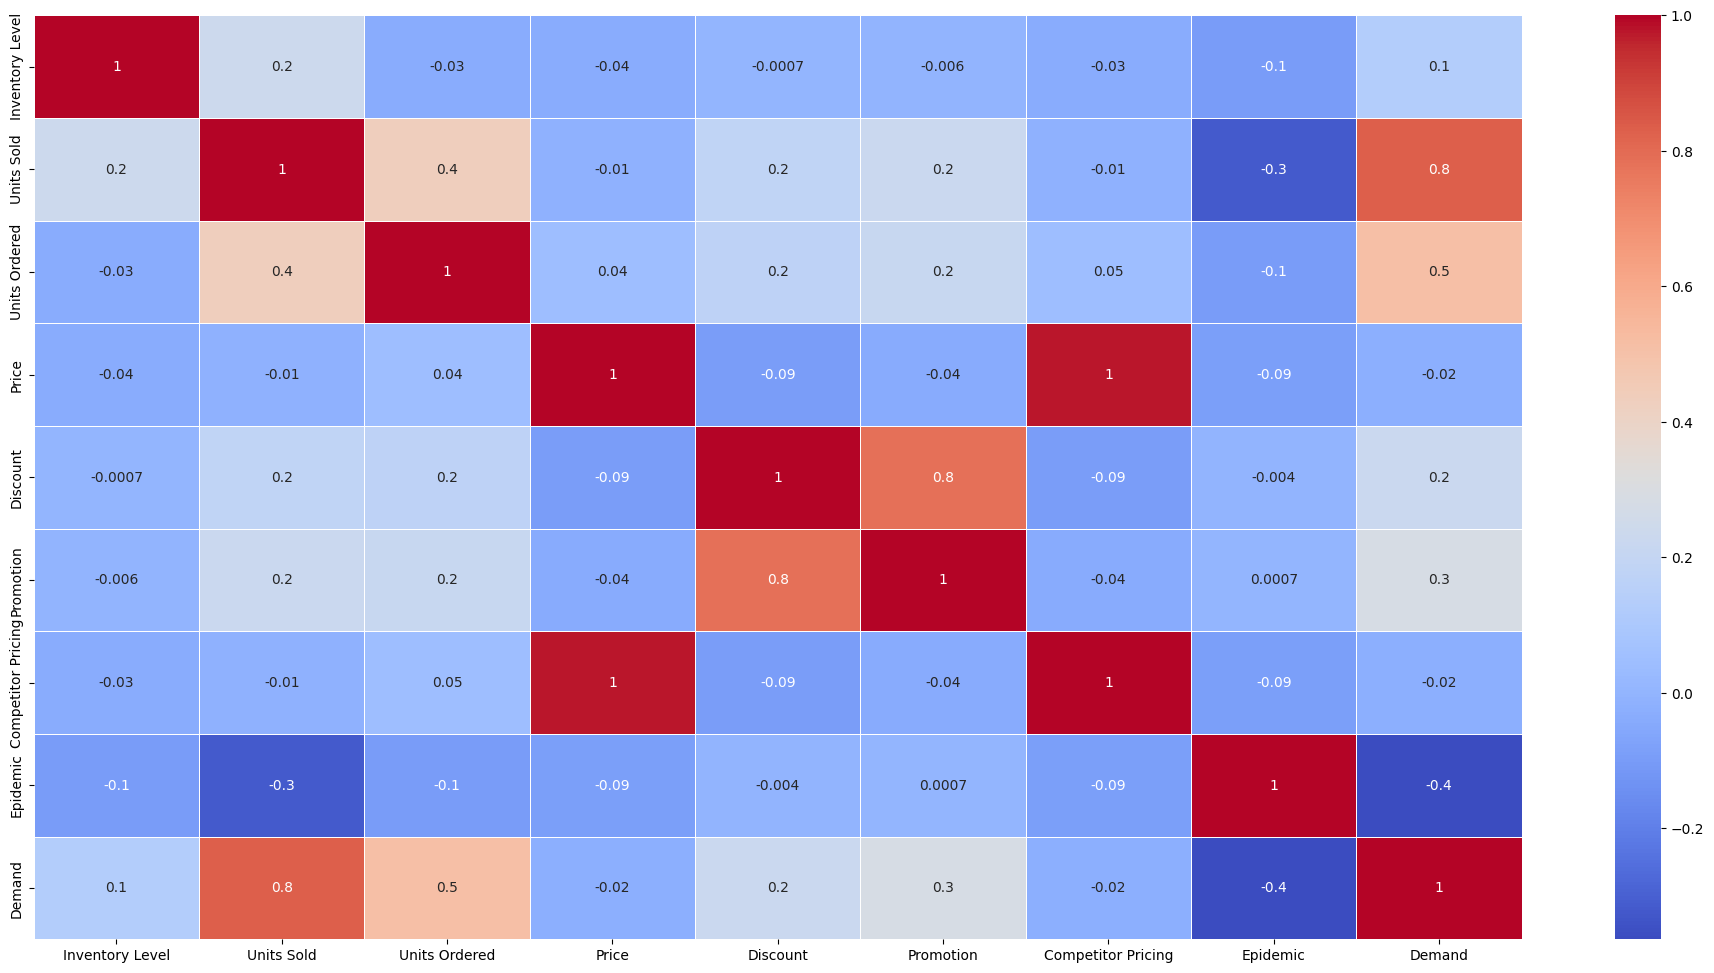

In [7]:
fig, ax = plt.subplots(figsize=(24, 12))

# Hitung korelasi hanya untuk kolom numerik
corr_matrix = df.corr(numeric_only=True)

# Tampilkan heatmap
sns.heatmap(corr_matrix, annot=True, linewidths=0.5, fmt='.1g', cmap='coolwarm', ax=ax)

plt.show()

<Axes: title={'center': 'Daily Demand Each Category'}, xlabel='Category'>

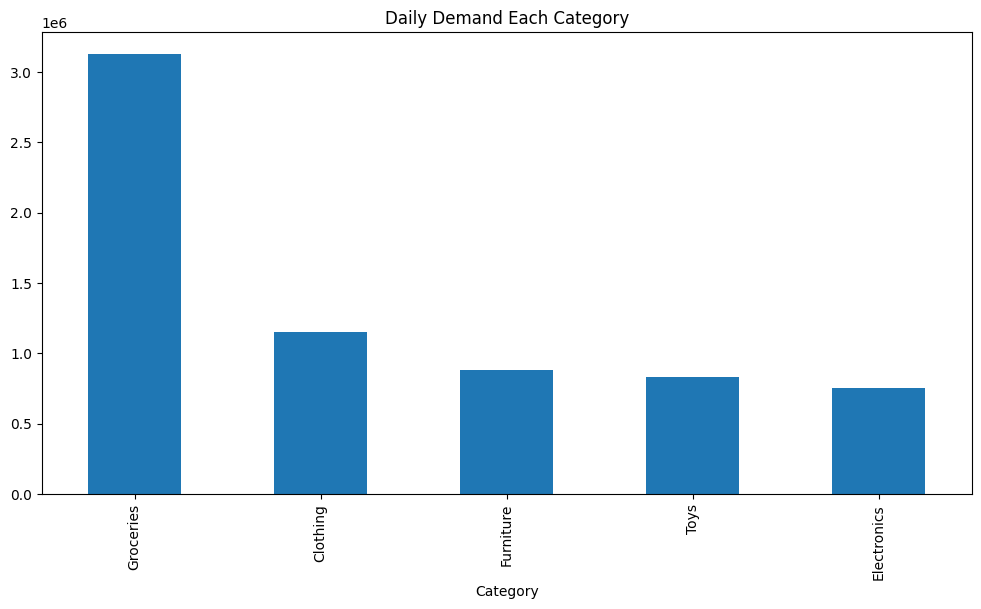

In [8]:
category = df.groupby('Category')
plt.figure(1)
category['Units Sold'].sum().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Daily Demand Each Category")

<Axes: title={'center': 'Daily Demand Each Category'}, xlabel='Category'>

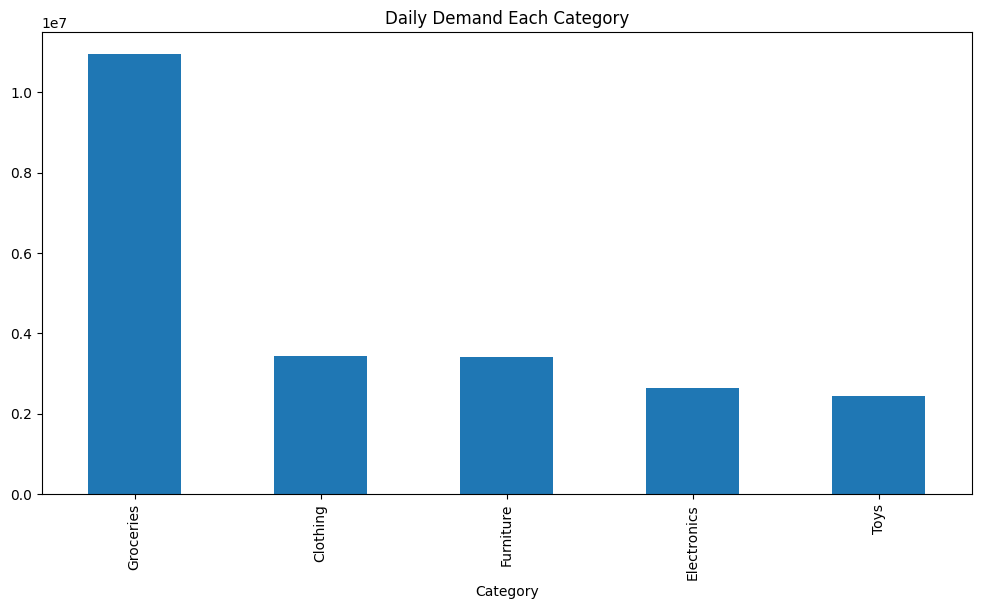

In [9]:
category = df.groupby('Category')
plt.figure(1)
category['Inventory Level'].sum().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Daily Demand Each Category")

In [10]:
train_data=df.copy()

In [11]:
# 1. Feature Engineering
df_feat = df.copy()
df_feat['Date'] = pd.to_datetime(df_feat['Date'])

# Extrak Fitur Waktu
df_feat['DayOfWeek'] = df_feat['Date'].dt.dayofweek
df_feat['Month'] = df_feat['Date'].dt.month
df_feat['Is_Weekend'] = df_feat['DayOfWeek'].isin([5, 6]).astype(int)

# Fitur Interaksi Bisnis
df_feat['Effective_Price'] = df_feat['Price'] * (1 - df_feat['Discount'] / 100.0)
df_feat['Price_Diff_Competitor'] = df_feat['Price'] - df_feat['Competitor Pricing']

# 2. Split Feature (X) & Target (y)
target_cols = ['Demand']
y = df_feat[target_cols]

columns_to_drop = ['Product ID', 'Store ID', 'Date'] + target_cols
x = df_feat.drop(columns=[col for col in columns_to_drop if col in df_feat.columns])

# One-Hot Encoding
categorical_cols = x.select_dtypes(include=['object']).columns.tolist()
x = pd.get_dummies(x, columns=categorical_cols, drop_first=True)

# 3. Train Test Split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

# 4. Scaling
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [12]:
# List penampung hasil evaluasi
results = []

def regressionmodel(model, x_train, x_test, y_train, y_test):
    # Fit model
    model = model.fit(x_train, y_train)

    # Prediksi data test
    y_pred = model.predict(x_test)

    # Hitung metrik evaluasi
    mae = metrics.mean_absolute_error(y_test, y_pred)
    mse = metrics.mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = metrics.r2_score(y_test, y_pred)
    mape = metrics.mean_absolute_percentage_error(y_test, y_pred)

    # Hitung Adjusted R2
    n = len(y_test)
    p = x_test.shape[1] if hasattr(x_test, 'shape') else 1
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

    # Print hasil
    print('Model : ', model)
    print("--------------------------------------------------")
    print(f"MAE  {target_cols}         :", mae)
    print(f"MSE  {target_cols}         :", mse)
    print(f"RMSE {target_cols}         :", rmse)
    print("R2                      :", r2)
    print("Adjusted R2             :", adj_r2)
    print(f"MAPE {target_cols}         :", mape)
    print("--------------------------------------------------")

    # Simpan hasil ke dalam list
    results.append({
        'Regression Model': model,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'MAPE': mape,
        'R2 Score': r2,
        'Adjusted R2': adj_r2
    })


    return model

In [13]:
model = Ridge(alpha=0.1)
regressionmodel(model, x_train, x_test, y_train, y_test)

Model :  Ridge(alpha=0.1)
--------------------------------------------------
MAE  ['Demand']         : 16.43583978870686
MSE  ['Demand']         : 485.08290110646357
RMSE ['Demand']         : 22.024597637788155
R2                      : 0.7798053146086892
Adjusted R2             : 0.7795539176991835
MAPE ['Demand']         : 0.19806774772417798
--------------------------------------------------


Ridge(alpha=0.1)

In [14]:
model = Lasso(alpha=0.1)
regressionmodel(model, x_train, x_test, y_train, y_test)

Model :  Lasso(alpha=0.1)
--------------------------------------------------
MAE  ['Demand']         : 16.450457402918683
MSE  ['Demand']         : 488.5604903917699
RMSE ['Demand']         : 22.10340449776391
R2                      : 0.7782267253060121
Adjusted R2             : 0.7779735261165315
MAPE ['Demand']         : 0.20166354505877782
--------------------------------------------------


Lasso(alpha=0.1)

In [15]:
model = lgb.LGBMRegressor(alpha=0.1, force_row_wise=True)
regressionmodel(model, x_train, x_test, y_train, y_test)

[LightGBM] [Info] Total Bins 1842
[LightGBM] [Info] Number of data points in the train set: 53200, number of used features: 26
[LightGBM] [Info] Start training from score 104.265771
Model :  LGBMRegressor(alpha=0.1, force_row_wise=True)
--------------------------------------------------
MAE  ['Demand']         : 12.848507280958353
MSE  ['Demand']         : 283.43588083052447
RMSE ['Demand']         : 16.83555406960295
R2                      : 0.8713393639195938
Adjusted R2             : 0.8711924716990656
MAPE ['Demand']         : 0.13821255029734203
--------------------------------------------------


LGBMRegressor(alpha=0.1, force_row_wise=True)

In [16]:
model = RandomForestRegressor(n_estimators=100,max_depth=10, random_state=40)
regressionmodel(model, x_train, x_test, y_train, y_test)

Model :  RandomForestRegressor(max_depth=10, random_state=40)
--------------------------------------------------
MAE  ['Demand']         : 13.44172923347325
MSE  ['Demand']         : 316.4045817219406
RMSE ['Demand']         : 17.787764944532537
R2                      : 0.8563738132807508
Adjusted R2             : 0.8562098348477512
MAPE ['Demand']         : 0.1406989473385135
--------------------------------------------------


RandomForestRegressor(max_depth=10, random_state=40)

In [17]:
model = xgb.XGBRegressor()
regressionmodel(model, x_train, x_test, y_train, y_test)

Model :  XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)
--------------------------------------------------
MAE  ['Demand']         : 12.444679260253906
MSE  ['Demand']         : 273.4307861328125
RMSE ['Demand']         : 16.535742684645662
R2                      : 0.8758809566497803
Adjusted R2 

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [18]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 600),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'gamma': trial.suggest_float('gamma', 0.0, 0.5),
        'random_state': 42,
        'n_jobs': -1
    }

    model = xgb.XGBRegressor(**params)
    model.fit(x_train, y_train)
    preds = model.predict(x_test)

    # Target optimasi: meminimalkan RMSE
    rmse = np.sqrt(metrics.mean_squared_error(y_test, preds))
    return rmse

# Jalankan optimasi
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30)  # Coba 30 iterasi

print("Parameter Terbaik dari Optuna:", study.best_params)

# Fit model akhir dengan parameter terbaik
best_xgb_optuna = xgb.XGBRegressor(**study.best_params, random_state=42, n_jobs=-1)
regressionmodel(best_xgb_optuna, x_train, x_test, y_train, y_test)

[I 2026-10-16 07:02:31,449] A new study created in memory with name: no-name-6dbd9dcf-bffd-4a83-b5cc-c0626256721c
[I 2026-10-16 07:02:34,564] Trial 0 finished with value: 16.127181977492416 and parameters: {'n_estimators': 304, 'max_depth': 9, 'learning_rate': 0.03594748113365615, 'subsample': 0.9012331014690007, 'colsample_bytree': 0.8454603684060904, 'min_child_weight': 6, 'gamma': 0.4802439269666994}. Best is trial 0 with value: 16.127181977492416.
[I 2026-10-16 07:02:39,466] Trial 1 finished with value: 16.27352095063817 and parameters: {'n_estimators': 219, 'max_depth': 10, 'learning_rate': 0.02801480636105672, 'subsample': 0.9349492521803502, 'colsample_bytree': 0.7470847764964998, 'min_child_weight': 1, 'gamma': 0.40659599476587}. Best is trial 0 with value: 16.127181977492416.
[I 2026-10-16 07:02:41,602] Trial 2 finished with value: 16.77392782090753 and parameters: {'n_estimators': 448, 'max_depth': 4, 'learning_rate': 0.19286055822295242, 'subsample': 0.8932196082871913, 'col

Parameter Terbaik dari Optuna: {'n_estimators': 408, 'max_depth': 10, 'learning_rate': 0.062013001033280266, 'subsample': 0.968092058227414, 'colsample_bytree': 0.8782064561497691, 'min_child_weight': 7, 'gamma': 0.03986298101638592}
Model :  XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8782064561497691, device=None,
             early_stopping_rounds=None, enable_categorical=True,
             eval_metric=None, feature_types=None, feature_weights=None,
             gamma=0.03986298101638592, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.062013001033280266,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=10, max_leaves=None,
             min_child_weight=7, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=408, n_jobs=-1,


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8782064561497691, device=None,
             early_stopping_rounds=None, enable_categorical=True,
             eval_metric=None, feature_types=None, feature_weights=None,
             gamma=0.03986298101638592, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.062013001033280266,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=10, max_leaves=None,
             min_child_weight=7, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=408, n_jobs=-1,
             num_parallel_tree=None, ...)

In [19]:
model = DecisionTreeRegressor()
regressionmodel(model, x_train, x_test, y_train, y_test)

Model :  DecisionTreeRegressor()
--------------------------------------------------
MAE  ['Demand']         : 17.5025
MSE  ['Demand']         : 588.2857456140351
RMSE ['Demand']         : 24.25460256557578
R2                      : 0.7329582337777663
Adjusted R2             : 0.7326533514205108
MAPE ['Demand']         : 0.18068773130981258
--------------------------------------------------


DecisionTreeRegressor()

In [20]:
model = LinearRegression()
regressionmodel(model, x_train, x_test, y_train, y_test)

Model :  LinearRegression()
--------------------------------------------------
MAE  ['Demand']         : 16.435803531235024
MSE  ['Demand']         : 485.08381692729876
RMSE ['Demand']         : 22.024618428642498
R2                      : 0.7798048988882418
Adjusted R2             : 0.7795535015041068
MAPE ['Demand']         : 0.19804978928356365
--------------------------------------------------


LinearRegression()

## Stacking Ensemble
Disisipkan setelah semua model tunggal dan **sebelum** tabel perbandingan serta pemilihan model terbaik (Entropy-TOPSIS), sehingga stacking ikut diranking bersama model lain.
- **Base model:** Ridge (linear), Random Forest (bagging), LightGBM dan XGBoost (boosting).
- **Meta-learner:** Ridge dengan bobot non-negatif (`positive=True`), sehingga koefisiennya terbaca sebagai kontribusi tiap base model.
- **Anti-leakage:** prediksi *out-of-fold* dari 5-fold CV pada data latih; data uji tidak disentuh saat pelatihan.
- Hasil evaluasi masuk ke list `results` lewat `regressionmodel()`, sama seperti model lainnya.

In [21]:
# =====================================================================
# STACKING ENSEMBLE (Stacked Generalization)
# Posisi: setelah model tunggal, sebelum tabel perbandingan & Entropy-TOPSIS
# =====================================================================
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import KFold

# Base model: sengaja dibuat beragam (linear, bagging, 2 jenis boosting)
base_models = [
    ('ridge', Ridge(alpha=0.1)),
    ('rf',    RandomForestRegressor(n_estimators=100, max_depth=10, random_state=40)),
    ('lgbm',  lgb.LGBMRegressor(force_row_wise=True, random_state=42, verbose=-1)),
    ('xgb',   xgb.XGBRegressor(random_state=42)),
]

# Meta-learner: linear sederhana dengan bobot non-negatif agar koefisien
# bisa dibaca sebagai kontribusi tiap base model
meta_learner = Ridge(alpha=1.0, positive=True)

stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=meta_learner,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),  # prediksi OOF -> tidak ada leakage
    n_jobs=-1,
    passthrough=False
)

# regressionmodel() otomatis menambahkan hasilnya ke list `results`,
# sehingga ikut diranking pada Entropy-TOPSIS di sel berikutnya
stacking_model = regressionmodel(stacking_model, x_train, x_test, y_train, y_test)

Model :  StackingRegressor(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                  estimators=[('ridge', Ridge(alpha=0.1)),
                              ('rf',
                               RandomForestRegressor(max_depth=10,
                                                     random_state=40)),
                              ('lgbm',
                               LGBMRegressor(force_row_wise=True,
                                             random_state=42, verbose=-1)),
                              ('xgb',
                               XGBRegressor(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            cols...
                                            importance_type=None,
                                            interaction_constraints=None,
    

In [22]:
# Buat DataFrame dari list results yang sudah terisi di sel sebelumnya
Regression_comparision = pd.DataFrame(results)

# Membersihkan nama model dari objek/string panjang
Regression_comparision['Regression Model'] = Regression_comparision['Regression Model'].apply(
    lambda x: type(x).__name__ if not isinstance(x, str) else x.split('(')[0]
)

Regression_comparision

,Regression Model,MAE,MSE,RMSE,MAPE,R2 Score,Adjusted R2
0,Ridge,16.435840,485.082901,22.024598,0.198068,0.779805,0.779554
1,Lasso,16.450457,488.560490,22.103404,0.201664,0.778227,0.777974
2,LGBMRegressor,12.848507,283.435881,16.835554,0.138213,0.871339,0.871192
3,RandomForestRegressor,13.441729,316.404582,17.787765,0.140699,0.856374,0.856210
4,XGBRegressor,12.444679,273.430786,16.535743,0.133276,0.875881,0.875739
5,XGBRegressor,11.860823,254.111252,15.940867,0.126498,0.884651,0.884519
6,DecisionTreeRegressor,17.502500,588.285746,24.254603,0.180688,0.732958,0.732653
7,LinearRegression,16.435804,485.083817,22.024618,0.198050,0.779805,0.779554
8,StackingRegressor,12.503853,271.296407,16.471078,0.132778,0.876850,0.876709


In [23]:
cost = ["MAE", "RMSE", "MAPE"]       # makin kecil makin baik
benefit = ["Adjusted R2"]           # makin besar makin baik
cols = cost + benefit
is_benefit = np.array([c in benefit for c in cols])
M = Regression_comparision[cols].values

# 1. Bobot Entropy
mn, mx = M.min(0), M.max(0)
X = np.where(is_benefit, (M - mn) / (mx - mn), (mx - M) / (mx - mn)) + 1e-12
P = X / X.sum(0)
e = -(P * np.log(P)).sum(0) / np.log(len(M))
w = (1 - e) / (1 - e).sum()

# 2. TOPSIS
V = M / np.sqrt((M ** 2).sum(0)) * w
best = np.where(is_benefit, V.max(0), V.min(0))
worst = np.where(is_benefit, V.min(0), V.max(0))
d_best = np.sqrt(((V - best) ** 2).sum(1))
d_worst = np.sqrt(((V - worst) ** 2).sum(1))

# --- PERBAIKAN: Gunakan Regression_comparision, bukan df ---
Regression_comparision["Skor TOPSIS"] = d_worst / (d_best + d_worst)
Regression_comparision["Rank"] = Regression_comparision["Skor TOPSIS"].rank(ascending=False).astype(int)

# Print Hasil
print("Bobot:", dict(zip(cols, w.round(4))))
print("\n=== HASIL PERINGKAT MODEL (TOPSIS) ===")
display(Regression_comparision.sort_values("Rank"))

model_terbaik = Regression_comparision.loc[Regression_comparision["Rank"] == 1, "Regression Model"].iloc[0]
print("\nModel terbaik:", model_terbaik)

Bobot: {'MAE': np.float64(0.2557), 'RMSE': np.float64(0.2135), 'MAPE': np.float64(0.3347), 'Adjusted R2': np.float64(0.1961)}

=== HASIL PERINGKAT MODEL (TOPSIS) ===


,Regression Model,MAE,MSE,RMSE,MAPE,R2 Score,Adjusted R2,Skor TOPSIS,Rank
5,XGBRegressor,11.860823,254.111252,15.940867,0.126498,0.884651,0.884519,1.000000,1
8,StackingRegressor,12.503853,271.296407,16.471078,0.132778,0.876850,0.876709,0.912642,2
4,XGBRegressor,12.444679,273.430786,16.535743,0.133276,0.875881,0.875739,0.910651,3
2,LGBMRegressor,12.848507,283.435881,16.835554,0.138213,0.871339,0.871192,0.849375,4
3,RandomForestRegressor,13.441729,316.404582,17.787765,0.140699,0.856374,0.856210,0.781642,5
6,DecisionTreeRegressor,17.502500,588.285746,24.254603,0.180688,0.732958,0.732653,0.194251,6
7,LinearRegression,16.435804,485.083817,22.024618,0.198050,0.779805,0.779554,0.155967,7
0,Ridge,16.435840,485.082901,22.024598,0.198068,0.779805,0.779554,0.155913,8
1,Lasso,16.450457,488.560490,22.103404,0.201664,0.778227,0.777974,0.144681,9



Model terbaik: XGBRegressor


In [24]:
def forecast(x_test, y_test, df_comparison, results_list):
    # Ambil baris dengan Rank == 1
    best_row = df_comparison.sort_values("Rank").iloc[0]

    # Ambil instance model terbaik dari results_list
    best_model_obj = None
    best_idx = best_row.name  # Index baris di df_comparison/results_list
    best_model_obj = results_list[best_idx]['Regression Model']

    if best_model_obj is None:
        raise ValueError("Model terbaik tidak ditemukan di results_list.")

    y_pred = best_model_obj.predict(x_test)

    df_forecast = pd.DataFrame({
        'Actual_Demand': y_test.values.ravel() if hasattr(y_test, 'values') else y_test,
        'Forecasted_Demand': y_pred
    })

    df_forecast['Error'] = df_forecast['Actual_Demand'] - df_forecast['Forecasted_Demand']
    df_forecast['Absolute_Error'] = np.abs(df_forecast['Error'])

    print(f"=== HASIL SIMULASI FORECAST MODEL TERBAIK ===")
    print(f"• Model Terpilih : {type(best_model_obj).__name__}")
    print(f"• RMSE           : {best_row['RMSE']:.4f}")
    print(f"• MAE            : {best_row['MAE']:.4f}")
    print(f"• R2 Score       : {best_row['R2 Score']:.4f}")

    return best_model_obj, df_forecast

# Eksekusi
best_model, df_simulasi_forecast = forecast(
    x_test=x_test,
    y_test=y_test,
    df_comparison=Regression_comparision,
    results_list=results
)

display(df_simulasi_forecast.head(10))

=== HASIL SIMULASI FORECAST MODEL TERBAIK ===
• Model Terpilih : XGBRegressor
• RMSE           : 15.9409
• MAE            : 11.8608
• R2 Score       : 0.8847


,Actual_Demand,Forecasted_Demand,Error,Absolute_Error
0,111,105.658829,5.341171,5.341171
1,81,78.898758,2.101242,2.101242
2,37,38.781342,-1.781342,1.781342
3,152,164.494858,-12.494858,12.494858
4,101,93.491905,7.508095,7.508095
5,137,132.750809,4.249191,4.249191
6,127,148.986755,-21.986755,21.986755
7,163,140.202728,22.797272,22.797272
8,164,143.487915,20.512085,20.512085
9,111,113.911095,-2.911095,2.911095


## Analisis Persediaan dari Hasil Demand Forecast
Memakai forecast model terbaik (`df_simulasi_forecast`) untuk: Kebijakan Persediaan (EOQ, Safety Stock, ROP), Stockout & Overstock, Biaya Persediaan, Analisis Lead Time, dan Analisis Service Level.

**Catatan:** dataset tidak memiliki lead time dan biaya, jadi parameter di `CFG` adalah asumsi yang perlu disesuaikan.

In [25]:
# =====================================================================
# ANALISIS PERSEDIAAN BERBASIS HASIL FORECAST (policy, stockout, biaya, lead time, service level)
# =====================================================================
from scipy.stats import norm

# Dataset tidak memuat lead time & biaya -> nilai di bawah adalah ASUMSI, silakan sesuaikan
CFG = dict(
    lead_time=3,         # hari, rata-rata lead time pemasok
    lt_std=1,            # hari, simpangan baku lead time
    service_level=0.95,  # target cycle service level
    order_cost=50,       # biaya pesan per order
    holding_rate=0.20,   # biaya simpan per tahun (% harga)
    margin=0.30,         # biaya stockout per unit (% harga = margin yang hilang)
    cover_days=5,        # overstock bila stok > cover_days x forecast harian
    days=365,
)
KEY = ['Store ID', 'Product ID']


def build_inventory_frame(df_feat, y_test, df_forecast):
    """Gabungkan forecast model terbaik dengan data aktual (index baris dipertahankan dari y_test)."""
    f = df_feat.loc[y_test.index, KEY + ['Category', 'Price', 'Inventory Level', 'Demand']].copy()
    f['Forecast'] = df_forecast['Forecasted_Demand'].clip(lower=0).values
    f['Error'] = f['Demand'] - f['Forecast']
    return f


def inventory_policy(f, c=CFG):
    """Kebijakan (s,Q) per Store-Produk: EOQ, Safety Stock, Reorder Point."""
    p = f.groupby(KEY).agg(Category=('Category', 'first'), Price=('Price', 'mean'),
                           d=('Forecast', 'mean'), sigma_e=('Error', 'std'))
    z = norm.ppf(c['service_level'])
    p['D'] = p['d'] * c['days']                                   # demand tahunan dari forecast
    p['H'] = c['holding_rate'] * p['Price']                       # biaya simpan/unit/tahun
    p['EOQ'] = np.sqrt(2 * p['D'] * c['order_cost'] / p['H'])
    p['sigma_L'] = np.sqrt(c['lead_time'] * p['sigma_e']**2 + (p['d'] * c['lt_std'])**2)
    p['SS'] = z * p['sigma_L']
    p['ROP'] = p['d'] * c['lead_time'] + p['SS']
    loss = norm.pdf(z) - z * norm.sf(z)                           # unit normal loss function
    p['Shortage'] = p['D'] / p['EOQ'] * p['sigma_L'] * loss       # ekspektasi kekurangan unit/tahun
    return p


def stockout_overstock(f, c=CFG):
    """Stockout (stok < demand aktual) dan overstock (stok > cover_days x forecast) per Store-Produk."""
    f = f.assign(Lost=(f['Demand'] - f['Inventory Level']).clip(lower=0),
                 Excess=(f['Inventory Level'] - f['Forecast'] * c['cover_days']).clip(lower=0))
    f['Stockout'], f['Overstock'] = f['Lost'] > 0, f['Excess'] > 0
    s = f.groupby(KEY).agg(Stockout_Rate=('Stockout', 'mean'), Overstock_Rate=('Overstock', 'mean'),
                           Avg_Lost=('Lost', 'mean'), Avg_Excess=('Excess', 'mean'),
                           Avg_Inv=('Inventory Level', 'mean'),
                           Lost=('Lost', 'sum'), Demand=('Demand', 'sum'))
    s['Fill_Rate'] = 1 - s.pop('Lost') / s.pop('Demand')
    return s


def inventory_cost(p, c=CFG, s=None):
    """Biaya tahunan kebijakan (pesan + simpan + stockout); bila s diberikan, bandingkan dengan kondisi aktual."""
    unit_loss = p['Price'] * c['margin']
    out = pd.DataFrame({'Ordering': p['D'] / p['EOQ'] * c['order_cost'],
                        'Holding': (p['EOQ'] / 2 + p['SS']) * p['H'],
                        'Stockout': p['Shortage'] * unit_loss})
    out['Total_Policy'] = out.sum(axis=1)
    if s is not None:
        out['Holding_Actual'] = s['Avg_Inv'] * p['H']
        out['Stockout_Actual'] = s['Avg_Lost'] * c['days'] * unit_loss
    return out


def sensitivity(f, key, values, c=CFG):
    """Ubah satu parameter di CFG, ringkas dampaknya ke seluruh item."""
    rows = []
    for v in values:
        cv = {**c, key: v}
        p = inventory_policy(f, cv)
        rows.append({key: v, 'Safety_Stock': p['SS'].sum(), 'Reorder_Point': p['ROP'].sum(),
                     'Fill_Rate': 1 - p['Shortage'].sum() / p['D'].sum(),
                     'Total_Cost': inventory_cost(p, cv)['Total_Policy'].sum()})
    return pd.DataFrame(rows).set_index(key)


def lead_time_analysis(f, values=(1, 2, 3, 5, 7, 10, 14), c=CFG):
    return sensitivity(f, 'lead_time', values, c)


def service_level_analysis(f, values=(0.85, 0.90, 0.95, 0.97, 0.99), c=CFG):
    return sensitivity(f, 'service_level', values, c)

In [26]:
# Eksekusi: gunakan hasil forecast model terbaik (df_simulasi_forecast) dan df_feat dari sel sebelumnya
frame  = build_inventory_frame(df_feat, y_test, df_simulasi_forecast)
policy = inventory_policy(frame)
status = stockout_overstock(frame)
cost   = inventory_cost(policy, CFG, status)

print("=== 1. Kebijakan Persediaan (5 item dengan ROP tertinggi) ===")
display(policy[['Category', 'd', 'EOQ', 'SS', 'ROP']].round(1).nlargest(5, 'ROP'))

print("\n=== 2. Stockout & Overstock (rata-rata seluruh item) ===")
display(status[['Stockout_Rate', 'Overstock_Rate', 'Fill_Rate']].mean().round(3).to_frame('Nilai').T)

print("\n=== 3. Biaya Persediaan Tahunan (total seluruh item) ===")
display(cost.sum().round(0).to_frame('Total').T)

print("\n=== 4. Analisis Lead Time ===")
display(lead_time_analysis(frame).round(3))

print("\n=== 5. Analisis Service Level ===")
display(service_level_analysis(frame).round(3))

=== 1. Kebijakan Persediaan (5 item dengan ROP tertinggi) ===


,,Category,d,EOQ,SS,ROP
Store ID,Product ID,,,,,
S005,P0009,Groceries,128.800003,498.5,216.6,603.0
S002,P0011,Groceries,128.600006,494.6,215.9,601.6
S003,P0015,Groceries,125.800003,484.3,211.6,589.1
S002,P0013,Groceries,125.300003,1002.1,212.5,588.6
S004,P0007,Groceries,125.099998,894.5,213.2,588.5



=== 2. Stockout & Overstock (rata-rata seluruh item) ===


,Stockout_Rate,Overstock_Rate,Fill_Rate
Nilai,0.135,0.208,0.943



=== 3. Biaya Persediaan Tahunan (total seluruh item) ===


,Ordering,Holding,Stockout,Total_Policy,Holding_Actual,Stockout_Actual
Total,338396.0,568654.0,339233.0,1246283.0,399586.0,3930255.0



=== 4. Analisis Lead Time ===


,Safety_Stock,Reorder_Point,Fill_Rate,Total_Cost
lead_time,,,,
1,17371.590,27818.996,0.996,1234918.886
2,17556.576,38451.388,0.996,1240631.759
3,17739.488,49081.707,0.996,1246283.224
5,18099.380,70336.412,0.996,1257410.052
7,18451.795,91583.640,0.996,1268314.480
10,18967.417,123441.481,0.996,1284283.284
14,19632.750,165896.438,0.996,1304911.703



=== 5. Analisis Service Level ===


,Safety_Stock,Reorder_Point,Fill_Rate,Total_Cost
service_level,,,,
0.85,11177.771,42519.990,0.985,2083371.972
0.90,13821.333,45163.551,0.991,1624890.864
0.95,17739.488,49081.707,0.996,1246283.224
0.97,20284.064,51626.283,0.998,1128718.943
0.99,25089.297,56431.516,0.999,1057470.650
